# Lung cancer classification using numerical data

This notebook uses the user-selected Akash Nath Kaggle dataset, version 2. It predicts source NO/YES labels from age and coded questionnaire inputs. The measured model is near chance; this is an academic workflow rather than a clinical risk estimator. No images are used.

In [1]:
from pathlib import Path
import sys
project=Path.cwd() if (Path.cwd()/'lung_tabular').exists() else Path.cwd().parent
sys.path.insert(0,str(project))
from lung_tabular import ROOT, DATA, REPORTS, ARTIFACTS, FEATURES
from lung_tabular.data import download_data, prepare_data, read_prepared
from lung_tabular.model import train_run, load_model, predict_records
from lung_tabular.utils import read_json
from IPython.display import display, Image
print('Project:',ROOT)

Project: C:\Users\ASUS\Desktop\Aiml Project


## Exact source and fixed data audit
The CSV source codes 1/2 are mapped to 0/1 without inventing clinical severity. Gender F/M maps to 0/1. Targets are NO/YES. Duplicate and conflicting feature profiles are handled before a fixed row split. Preprocessing fits only on training folds.

In [2]:
if not (DATA/'lung_cancer.csv').exists():
    download_data()
prepare_data()
records, summary=read_prepared()
display({key:summary[key] for key in ['raw_rows','usable_rows','duplicate_rows_removed','conflicting_rows_removed','age_range','split_counts','csv_sha256']})
display(summary['source']['source_page'])

{'raw_rows': 3000,
 'usable_rows': 2994,
 'duplicate_rows_removed': 2,
 'conflicting_rows_removed': 4,
 'age_range': [30, 80],
 'split_counts': {'train': {'NO': 1183, 'YES': 1212},
  'test': {'NO': 296, 'YES': 303}},
 'csv_sha256': '417052af60ea9da985478d93d6be49749d25c8d0168a14bbd9f94515ab80c6ce'}

'https://www.kaggle.com/datasets/akashnath29/lung-cancer-dataset'

## Training
The saved initial run is reused by default. Set RETRAIN=True and a new run name to explicitly train again. The initial test partition has already been viewed; later runs report training CV only and do not claim a fresh test score.

In [3]:
RETRAIN=False
NEW_RUN_NAME='notebook_numerical_01'
initial=ARTIFACTS/'numerical_v1'
if not (initial/'metadata.json').exists():
    train_run('numerical_v1')
if RETRAIN:
    display(train_run(NEW_RUN_NAME))
metadata=read_json(initial/'metadata.json')
import pandas as pd
display(pd.DataFrame(metadata['comparison']))
print(metadata['quality_note'])
print('Initial training seconds:',metadata['training_seconds'])

,model,cv_macro_f1,cv_macro_f1_std,cv_balanced_accuracy,cv_balanced_accuracy_std,cv_roc_auc,cv_roc_auc_std
0,hist_gradient_boosting,0.523611,0.018741,0.524225,0.018451,0.530945,0.014611
1,logistic_C0.1,0.512950,0.009968,0.513107,0.010032,0.511445,0.015814
2,logistic_C1,0.512535,0.010731,0.512685,0.010804,0.511508,0.015786
3,random_forest_full,0.509288,0.002972,0.509315,0.002966,0.519410,0.010955
4,random_forest_depth6,0.508898,0.004857,0.508994,0.004842,0.521534,0.008524


Performance is near chance. This dataset/model has not demonstrated reliable predictive skill.
Initial training seconds: 7.023670599999605


## Saved held-out evaluation
The selected model was frozen using training-only CV before this evaluation. Reading saved results does not run the test set again. The weak score must be compared with the majority-label baseline, not the old CT-image validation score.

{'records': 599,
 'accuracy': 0.5091819699499165,
 'balanced_accuracy': 0.5098563910445099,
 'macro_f1': 0.5078638497652582,
 'roc_auc': 0.5308792703594684,
 'accuracy_wilson_95': [0.4692169486578002, 0.549029971554885],
 'confusion_matrix': [[168, 128], [166, 137]]}

Majority baseline accuracy: 0.5058430717863105


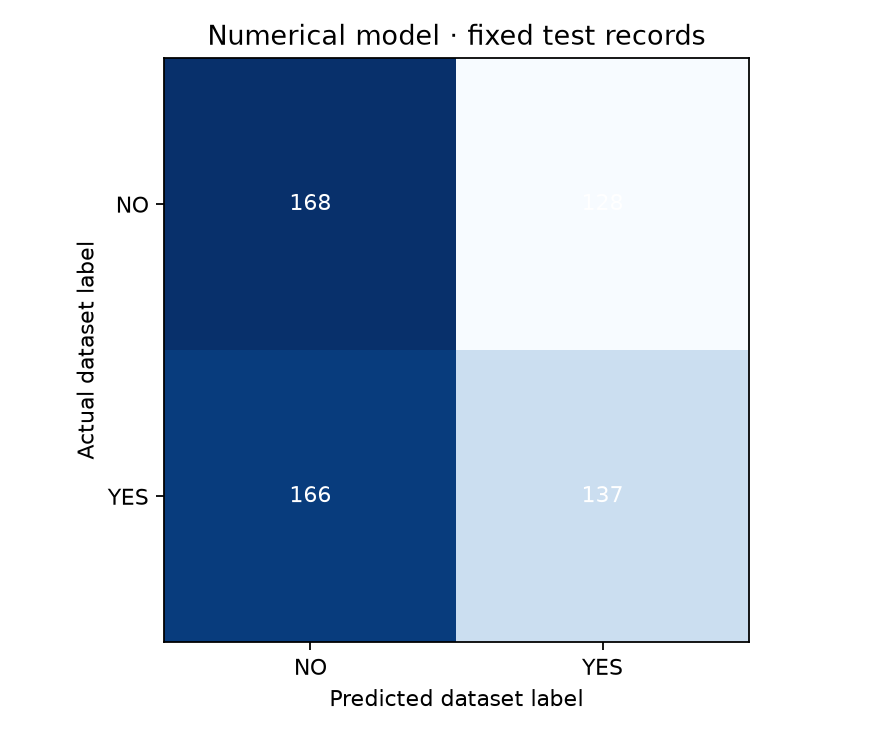

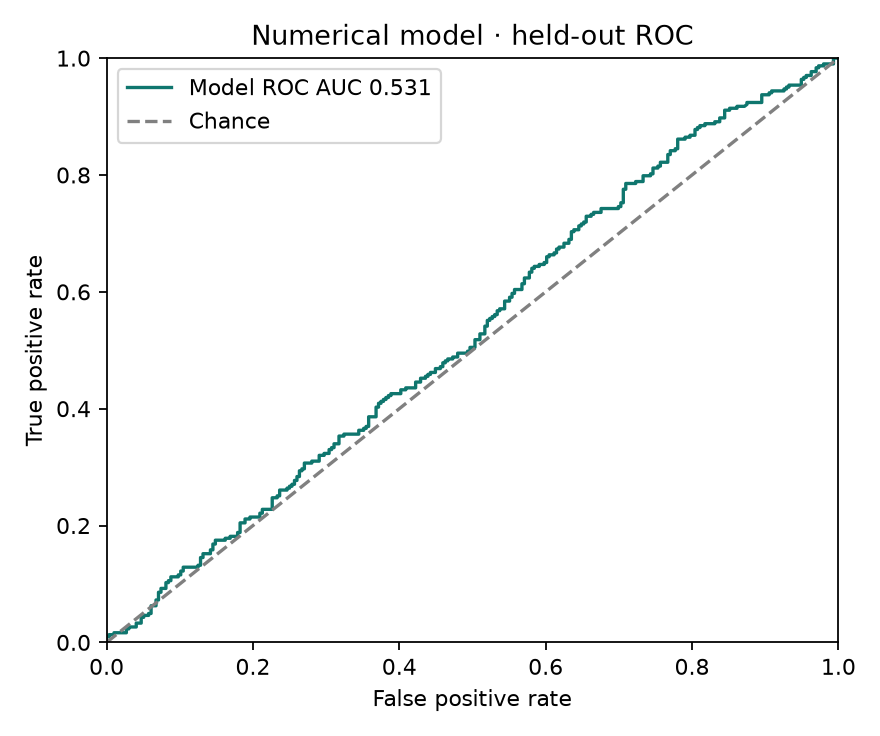

In [4]:
evaluation=read_json(REPORTS/'test_evaluation.json')
display({key:evaluation[key] for key in ['records','accuracy','balanced_accuracy','macro_f1','roc_auc','accuracy_wilson_95','confusion_matrix']})
print('Majority baseline accuracy:',evaluation['baseline']['accuracy'])
display(Image(filename=str(REPORTS/'confusion_matrix.png')))
display(Image(filename=str(REPORTS/'roc_curve.png')))

## Numerical prediction
This example is a training record chosen by row hash rather than correctness. The input contains no target column. Model scores are not personal cancer probabilities.

In [5]:
model, metadata=load_model(initial)
example=records.loc[records.split=='train',list(FEATURES)].head(2)
display(example)
display(predict_records(example,model,metadata))

,AGE,GENDER,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC_DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL_CONSUMING,COUGHING,SHORTNESS_OF_BREATH,SWALLOWING_DIFFICULTY,CHEST_PAIN
0,53,1,1,1,0,0,0,1,0,0,0,1,1,1,1
1,35,0,1,1,1,1,0,1,1,1,0,0,0,0,1


,AGE,GENDER,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC_DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL_CONSUMING,COUGHING,SHORTNESS_OF_BREATH,SWALLOWING_DIFFICULTY,CHEST_PAIN,predicted_dataset_label,no_model_score,yes_model_score,model_run,model_sha256
0,53,1,1,1,0,0,0,1,0,0,0,1,1,1,1,YES,0.466741,0.533259,numerical_v1,b03b0498c128de3028234b7fbbed9abe227f0e2e26de97...
1,35,0,1,1,1,1,0,1,1,1,0,0,0,0,1,YES,0.366857,0.633143,numerical_v1,b03b0498c128de3028234b7fbbed9abe227f0e2e26de97...


## Run the app and inspect the project
Run `powershell -ExecutionPolicy Bypass -File .\run.ps1` from the project folder and open http://localhost:8501. The application supports complete numerical entry, CSV templates, explicit encoding, batch downloads, and measured results. Read `reports/FINAL_REPORT.md`, `docs/DATASET_CARD.md`, and `docs/MODEL_CARD.md`. The earlier image project is preserved in `legacy_ct/` and is excluded from the numerical application.